# Avance 5. Modelos base para los ensambles

**Inferencia de propiedades físicas de galaxias a partir de imágenes multibanda** · Instituto Tecnológico y de Estudios Superiores de Monterrey · Maestría en Inteligencia Artificial Aplicada · **Equipo 24** · Colaboración con el Instituto de Astronomía de la UNAM

| Integrante | Matrícula |
|---|---|
| Luz Copelia Minutti Pérez | A01796921 |
| Erick Alberto Bustos Cruz | A01378966 |
| José Florencio Maguey Peralta | A01796727 |

**Asesores:** Dr. Iván Reyes Amezcua (ITESM) · Dr. Héctor Hernández Toledo y Dr. José Antonio Vázquez Mata (IA-UNAM)

**Fase de CRISP-ML(Q):** 3, *Machine Learning Model Engineering* (Studer et al. 2021). **Avance 5:** modelo final.

## 1. Planteamiento

Este cuaderno prepara los modelos base con los que construimos los ensambles del Avance 5. Un ensamble solo mejora a sus miembros si estos son buenos y, además, se equivocan de formas distintas: el error del ensamble es el error medio de los miembros menos su desacuerdo (Krogh y Vedelsby 1995). Por eso aquí hacemos tres cosas. Recuperamos y exportamos las predicciones de las redes que ya entrenamos en el Avance 4, ConvNeXt-Tiny y DINOv3. Entrenamos sus versiones con el redshift espectroscópico como entrada, igual que la variante E de ResNet50 del modelo 1. Y agregamos una familia nueva de redes, EfficientNet-B3.

La segunda parte viene de la física del problema. La masa estelar depende de la luminosidad, y la luminosidad de una galaxia no se puede calcular a partir de su brillo aparente sin conocer su distancia. La variante E de ResNet50 lo muestra: al agregar el redshift, el criterio pasó de 0.178 a 0.129, casi todo por la masa. En el Avance 4 le dimos a nuestros modelos un redshift estimado desde la imagen, pero su error mediano de 20 % equivale a unos 0.16 dex de error en la luminosidad, comparable con el error de masa que ya teníamos, y no ayudó. Con el redshift medido el error de la distancia es despreciable. Nuestra hipótesis es que DINOv3 y ConvNeXt con el redshift medido reúnen la ventaja del ResNet50 en la masa con la de DINOv3 en la SFR y el D4000. La ponemos a prueba comparando cada modelo con su versión sin redshift y con la variante E.

EfficientNet-B3 es la arquitectura que mejor resultó a Zhong et al. (2024) al estimar masa estelar y sSFR con imágenes de DESI, y pertenece a una familia distinta de las que ya tenemos. La incorporamos por su diversidad, que es lo que un ensamble necesita, sin suponer que vaya a superar a los demás modelos por sí sola.

**El interruptor de la pista.** El redshift espectroscópico existe para las galaxias de MaNGA, pero no para la mayoría de las galaxias que solo tienen imagen, que son a las que nos interesa extender las estimaciones. Por eso trabajamos con dos pistas y las separamos con una sola variable, `PISTA`, en la sección de parámetros. Con `con_redshift` (valor por defecto) se entrenan DINOv3, ConvNeXt y EfficientNet con el redshift medido. Con `solo_imagen` solo se entrena EfficientNet sin redshift. En ambos casos se exportan las predicciones de las redes de solo imagen del Avance 4, porque son los miembros de la segunda pista y, en la primera, la referencia contra la que medimos el efecto del redshift.

Este cuaderno exporta las predicciones de prueba pero no las evalúa. La única evaluación en prueba ocurre en el cuaderno de ensambles, una sola vez, después de registrar la elección del modelo final.

## 2. Parámetros

| Parámetro | Valor | Significado |
|---|---|---|
| `PISTA` | `con_redshift` | Interruptor de la pista: `con_redshift` o `solo_imagen`. Define qué modelos nuevos se entrenan |
| `SEMILLAS` | 42, 7, 2026 | Semillas de cada entrenamiento, las mismas del Avance 4 |
| `USAR_TTA` | sí | Las predicciones exportadas promedian las 8 simetrías de la imagen |
| `INCLUIR_EFFICIENTNET` | sí | Si se busca y entrena EfficientNet-B3 |
| `PRUEBAS_EFFICIENTNET` | 12 | Configuraciones que prueba la búsqueda de hiperparámetros |
| `EPOCAS_EFFICIENTNET` | 20 | Épocas de cada prueba y de cada entrenamiento final; usamos la misma duración en ambos porque en el Avance 4 vimos que el orden de las configuraciones cambia al entrenar más tiempo |
| `N_REMUESTREOS` | 2000 | Remuestreos *bootstrap* para los intervalos de confianza |
| `MARGEN` | 0.02, 0.02, 0.01 | Diferencia de RMSE que se considera despreciable en log M\*, log SFR y D4000 |

Los modelos de DINOv3 y ConvNeXt con redshift toman su arquitectura y sus hiperparámetros de los ganadores del Avance 4, que se leen de las carpetas de sus corridas. La única diferencia es la entrada.

In [1]:
import os
variable_entorno = os.environ.get          # las variables MA_* solo se usan en la prueba local reducida

# ------------------------------------------------------------------------------------------------
# INTERRUPTOR DE LA PISTA: "con_redshift" (redshift espectroscópico como entrada) o "solo_imagen".
PISTA = "con_redshift"
# ------------------------------------------------------------------------------------------------
PISTA = variable_entorno("MA_PISTA", PISTA)
PISTAS = {"con_redshift": ("redshift",), "solo_imagen": ()}
if PISTA not in PISTAS:
    raise ValueError(f"PISTA debe ser una de {list(PISTAS)}")
VARIABLES_PISTA = PISTAS[PISTA]
SUFIJO_PISTA = "z" if VARIABLES_PISTA else "imagen"

SEMILLAS = tuple(int(s) for s in variable_entorno("MA_SEMILLAS", "42,7,2026").split(","))
USAR_TTA = variable_entorno("MA_TTA", "1") == "1"
INCLUIR_EFFICIENTNET = variable_entorno("MA_EFFICIENTNET", "1") == "1"
PRUEBAS_EFFICIENTNET = int(variable_entorno("MA_PRUEBAS_EFFICIENTNET", "12"))
EPOCAS_EFFICIENTNET = int(variable_entorno("MA_EPOCAS_EFFICIENTNET", "20"))
EXTRACTOR_EFFICIENTNET = variable_entorno("MA_EXTRACTOR_EFFICIENTNET", "efficientnet_b3.ra2_in1k")
LADO_EFFICIENTNET = int(variable_entorno("MA_LADO_EFFICIENTNET", "300"))
N_REMUESTREOS = int(variable_entorno("MA_REMUESTREOS", "2000"))
LIMITE_GALAXIAS = int(variable_entorno("MA_LIMITE", "0"))           # 0 = todas las galaxias
PREENTRENADO = variable_entorno("MA_PREENTRENADO", "1") == "1"
HARDWARE_AVANCE4 = "NVIDIA A100 (Colab)"                            # donde se entrenaron las redes del Avance 4

from pathlib import Path
BASE_DRIVE = Path(variable_entorno("MA_BASE", "/content/drive/MyDrive"))
CARPETA_RESULTADOS = "resultados_modelos_alternativos"
NOMBRE_MODELO = "avance5_modelos_base"
OBJETIVOS = ("log_mstar", "log_sfr", "d4000")
NOMBRES = {"log_mstar": "log M* [dex]", "log_sfr": "log SFR [dex]", "d4000": "D4000"}
CORTO = {"log_mstar": "M*", "log_sfr": "SFR", "d4000": "D4000"}
MARGEN = {"M*": 0.02, "SFR": 0.02, "D4000": 0.01}
CORTE_SSFR = -10.8                                                   # frontera entre galaxias formadoras y apagadas
ENTRADA_BASE = {"representacion": "grz_estandarizado", "lado": 300, "modo_lado": "recorte"}
ENTRADA_EFFICIENTNET = {"representacion": "grz_estandarizado", "lado": LADO_EFFICIENTNET, "modo_lado": "recorte"}
print(f"Pista: {PISTA} · entradas de los modelos nuevos: imagen" + (" + redshift espectroscópico" if VARIABLES_PISTA else ""))

Pista: con_redshift · entradas de los modelos nuevos: imagen + redshift espectroscópico


## 3. Entorno

Descargamos el código del repositorio del equipo, de modo que cada resultado quede ligado a una versión concreta, e instalamos las bibliotecas que Colab no incluye: `timm` (modelos preentrenados) y `optuna` (búsqueda de hiperparámetros). Este cuaderno necesita una GPU; recomendamos una A100. Si la sesión se interrumpe, al volver a ejecutarlo se retoman los entrenamientos ya terminados.

In [2]:
import sys, json, time, subprocess, platform, warnings
from pathlib import Path
from dataclasses import replace

EN_COLAB = "google.colab" in sys.modules
URL_REPOSITORIO = "https://github.com/erteck/InferenciaPropiedadesFisicas.git"
CARPETA_REPOSITORIO = Path(variable_entorno("MA_CARPETA_REPOSITORIO", "/content/InferenciaPropiedadesFisicas"))
if EN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm>=1.0.20", "optuna>=4", "hickle"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    if not CARPETA_REPOSITORIO.exists():
        subprocess.run(["git", "clone", "-q", URL_REPOSITORIO, str(CARPETA_REPOSITORIO)], check=True)
    subprocess.run(["git", "-C", str(CARPETA_REPOSITORIO), "pull", "-q"], check=True)
sys.path.insert(0, str(CARPETA_REPOSITORIO))
COMMIT = subprocess.run(["git", "-C", str(CARPETA_REPOSITORIO), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()

warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch, timm, optuna
import matplotlib.pyplot as plt
from IPython.display import display

from src.modelos_alternativos import arquitecturas, busqueda, evaluacion, experimento, interpretacion
from src.modelos_alternativos.arquitecturas import EspecificacionModelo
from src.modelos_alternativos.contexto import preparar_contexto
from src.modelos_alternativos.entrenamiento import ConfiguracionEntrenamiento
from src.katachi_fits.diagnostico import radio_mitad_luz

DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
pd.set_option("display.precision", 4, "display.max_columns", 40, "display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
print("Python", platform.python_version(), "· commit", COMMIT[:12], "· timm", timm.__version__, "· optuna", optuna.__version__,
      "·", DISPOSITIVO, torch.cuda.get_device_name(0) if DISPOSITIVO.type == "cuda" else "")

Mounted at /content/drive
Python 3.13.16 · commit 33b868a7da2a · timm 1.0.30 · optuna 5.0.0 · cuda NVIDIA A100-SXM4-40GB


In [3]:
from datetime import datetime, timezone
from src.modelos_alternativos import ensambles, predicciones
from src.modelos_alternativos.arquitecturas import EspecificacionModelo
CARPETA_CONVNEXT = BASE_DRIVE / CARPETA_RESULTADOS / "modelo3_convnext_tiny_imagen"
CARPETA_DINOV3 = BASE_DRIVE / CARPETA_RESULTADOS / "modelo4_dinov3_imagen"
NOMBRE_GPU = torch.cuda.get_device_name(0) if DISPOSITIVO.type == "cuda" else "CPU"

## 4. Datos

Preparamos la muestra y las transformaciones con las reglas del protocolo común. Todos los parámetros (la escala de compresión de cada banda y las medias y desviaciones de la imagen y de las etiquetas) se calculan solo con las galaxias de entrenamiento y se aplican sin cambios a validación y prueba. Los conteos de la muestra se calculan aquí, no se imponen.

In [4]:
CONTEXTO = preparar_contexto(BASE_DRIVE, CARPETA_RESULTADOS, OBJETIVOS, limite_galaxias=LIMITE_GALAXIAS)
CARPETA_MODELO = CONTEXTO.guardia.mkdir(BASE_DRIVE / CARPETA_RESULTADOS / NOMBRE_MODELO)
MUESTRA, INDICES = CONTEXTO.muestra, CONTEXTO.indices
TIPO_GALAXIA = np.where(MUESTRA.log_ssfr < CORTE_SSFR, "apagada", "formadora")
display(pd.crosstab(MUESTRA.particion, pd.Series(TIPO_GALAXIA, name="tipo de galaxia", index=MUESTRA.index), margins=True,
                    margins_name="total").loc[["Train", "Validation", "Test", "total"]])
if len(CONTEXTO.excluidas):
    display(CONTEXTO.excluidas.groupby(["particion", "motivo"]).size().rename("galaxias").reset_index())
t = CONTEXTO.transformacion_grz
display(pd.DataFrame({"s_b (percentil 75 de |f|)": t.escala_asinh, "media tras asinh": t.media, "desviación tras asinh": t.desviacion},
                     index=["g", "r", "z"]).round(5))
RADIO_MITAD_LUZ = radio_mitad_luz(CONTEXTO.imagenes, banda=1)          # en píxeles de la imagen de 300 px, banda r
print(f"Radio de mitad de luz (banda r): mediana {np.median(RADIO_MITAD_LUZ):.1f} px")

Muestra: 9299 galaxias (Train 7121, Validation 1261, Test 917) · excluidas: 4


tipo de galaxia,apagada,formadora,total
particion,,,
Train,3745,3376,7121
Validation,676,585,1261
Test,465,452,917
total,4886,4413,9299


,particion,motivo,galaxias
0,Test,banda completa en cero,1
1,Train,banda completa en cero,1
2,Train,redshift no válido,1
3,Validation,banda completa en cero,1


,s_b (percentil 75 de |f|),media tras asinh,desviación tras asinh
g,0.0039,0.4967,1.0310
r,0.0074,0.5076,1.0334
z,0.0161,0.3651,0.9897


Radio de mitad de luz (banda r): mediana 22.1 px


La figura muestra lo que recibe la red: los tres canales estandarizados (z, r y g como rojo, verde y azul) en el recorte central de 300 × 300 píxeles, que es la entrada de ConvNeXt y de EfficientNet (DINOv3 recibe un recorte de 288 píxeles en color de Lupton). Las galaxias van de menor a mayor masa, y en ellas se ve lo que el modelo tiene que aprender a leer: el color se vuelve más rojo y la luz más concentrada al aumentar la masa y bajar la formación de estrellas. El círculo marca el radio que encierra la mitad de la luz (R50), la escala con la que después medimos qué regiones de la galaxia usa el modelo.

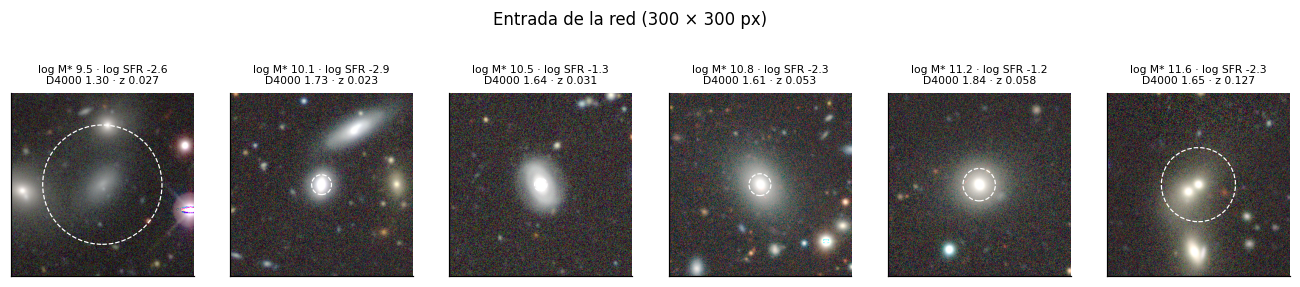

In [5]:
PREPARADOR_VISTA = experimento.crear_preparador(CONTEXTO, ENTRADA_BASE)
entrenamiento = MUESTRA.iloc[INDICES["Train"]]
ejemplos = [entrenamiento.index[np.argmin(np.abs(entrenamiento.log_mstar.to_numpy() - q))]
            for q in np.quantile(entrenamiento.log_mstar, np.linspace(0.05, 0.95, 6))]
fig, ejes = plt.subplots(1, 6, figsize=(15, 2.9))
for eje, i in zip(ejes, ejemplos):
    x = PREPARADOR_VISTA(torch.from_numpy(CONTEXTO.imagenes[i:i + 1].astype(np.float32)))[0].numpy()[[2, 1, 0]]
    if PREPARADOR_VISTA.representacion == "rgb_lupton":
        x = x[[2, 1, 0]]
    rgb = np.transpose(x, (1, 2, 0)); rgb = np.clip((rgb - np.percentile(rgb, 1)) / (np.percentile(rgb, 99.7) - np.percentile(rgb, 1)), 0, 1)
    eje.imshow(rgb, origin="lower")
    escala = x.shape[-1] / 300 if PREPARADOR_VISTA.modo_lado == "reescala" else 1
    eje.add_patch(plt.Circle(((x.shape[-1] - 1) / 2,) * 2, RADIO_MITAD_LUZ[i] * escala, fill=False, color="w", lw=0.8, ls="--"))
    g = MUESTRA.loc[i]
    eje.set_title(f"log M* {g.log_mstar:.1f} · log SFR {g.log_sfr:.1f}\nD4000 {g.d4000:.2f} · z {g.redshift:.3f}", fontsize=7)
    eje.set_xticks([]); eje.set_yticks([])
plt.suptitle(f"Entrada de la red ({x.shape[-1]} × {x.shape[-1]} px)", y=1.04); plt.show()

In [6]:
# Utilidades para resumir corridas con las métricas del protocolo común.
def registro_compacto(mensaje):
    # Durante el entrenamiento solo se muestra el avance cada 5 épocas.
    if mensaje.startswith("época") and int(mensaje.split()[1]) % 5 == 0:
        print(mensaje)

def registro_busqueda(mensaje):
    # De la búsqueda solo se muestran las pruebas que fallan.
    if "falló" in mensaje:
        print(mensaje)

def grafica_hiperparametros(pruebas, importancia, referencia=None, n=3, titulo="", siempre=(), etiqueta_referencia="configuración de partida"):
    # Criterio de validación frente a los n hiperparámetros más importantes de la búsqueda (más los de `siempre`).
    terminadas = pruebas[pruebas.estado == "complete"]
    nombres = [h for h in siempre if h in terminadas]
    nombres += [h for h in (importancia.index if len(importancia) else []) if h in terminadas and h not in nombres][:max(0, n - len(nombres))]
    if not nombres:
        return
    fig, ejes = plt.subplots(1, len(nombres) + 1, figsize=(4.2 * (len(nombres) + 1), 3.4))
    orden = terminadas.sort_values("prueba")
    ejes[0].scatter(orden.prueba, orden.criterio_validacion, s=16, color="#264653")
    ejes[0].plot(orden.prueba, orden.criterio_validacion.cummin(), color="C3", lw=1, label="mejor hasta el momento")
    if referencia is not None:
        ejes[0].axhline(referencia, color="k", ls=":", lw=1, label=etiqueta_referencia)
    ejes[0].set(xlabel="prueba", ylabel="criterio de validación", title="Avance de la búsqueda"); ejes[0].legend(fontsize=7)
    for eje, h in zip(ejes[1:], nombres):
        valores = terminadas[h]
        if pd.api.types.is_numeric_dtype(valores):
            eje.scatter(valores, terminadas.criterio_validacion, s=16, color="#264653")
            if (valores > 0).all() and valores.max() / valores.min() > 3:
                eje.set_xscale("log")
        else:
            categorias = sorted(valores.astype(str).unique())
            posicion = valores.astype(str).map({k: n for n, k in enumerate(categorias)})
            eje.scatter(posicion + np.random.default_rng(0).uniform(-0.12, 0.12, len(posicion)), terminadas.criterio_validacion,
                        s=16, color="#264653", alpha=0.7)
            medianas = terminadas.groupby(valores.astype(str)).criterio_validacion.median()
            eje.scatter(range(len(categorias)), [medianas[k] for k in categorias], marker="_", s=600, color="C3", label="mediana")
            eje.set_xticks(range(len(categorias)), [k.split(".")[-1] for k in categorias], rotation=15)
            eje.set_xlim(-0.6, len(categorias) - 0.4)
        importancia_h = f" · importancia {importancia[h]:.2f}" if h in importancia else ""
        eje.set(xlabel=h.replace("_", " "), title=f"{h.replace('_', ' ')}{importancia_h}")
    ejes[0].xaxis.get_major_locator().set_params(integer=True)
    ejes[1].set_ylabel("criterio de validación")
    plt.suptitle(titulo, y=1.03); plt.tight_layout(); plt.show()
def metricas_corrida(corrida, particion="Validation", tta=False):
    prediccion = experimento.predicciones_originales(CONTEXTO, corrida, particion, DISPOSITIVO, tta=tta)
    return experimento.tabla_corrida(CONTEXTO, prediccion, particion, corrida=corrida.identificador), prediccion

def resumen_corridas(corridas, etiqueta, particion="Validation"):
    # Media y desviación entre semillas de cada métrica; fila ancha por modelo.
    tablas = pd.concat([metricas_corrida(r, particion)[0].assign(semilla=r.resumen["configuracion"]["semilla"]) for r in corridas])
    variables = corridas[0].variables_escalares
    fila = {"modelo": etiqueta, "entradas": "solo imagen" if not variables else "imagen + " + ", ".join(variables).replace("_", " "),
            "solo_imagen_al_predecir": "sí", "semillas": len(corridas),
            "MSE_normalizado_medio": tablas.groupby("semilla").MSE_normalizado.mean().mean(),
            "desviacion_entre_semillas": tablas.groupby("semilla").MSE_normalizado.mean().std(ddof=1) if len(corridas) > 1 else np.nan}
    for objetivo, g in tablas.groupby("objetivo", sort=False):
        for m in ("RMSE", "MAE", "sesgo", "R2"):
            fila[f"{m} {CORTO[objetivo]}"] = g[m].mean()
    fila["minutos_entrenamiento"] = np.mean([r.resumen["minutos_entrenamiento"] for r in corridas])
    fila["parametros_entrenables_M"] = corridas[0].resumen["parametros_entrenables"] / 1e6
    return fila, tablas

## 5. Redes del Avance 4: recuperación y exportación

Las redes de ConvNeXt-Tiny y de DINOv3 con LoRA que entrenamos en el Avance 4 siguen guardadas con sus pesos y su configuración. No las volvemos a entrenar: las recuperamos, predecimos con ellas las galaxias de validación y de prueba, y guardamos las predicciones en el formato común.

Encontramos las corridas automáticamente. En el caso de DINOv3 son las tres corridas del ajuste final. En el de ConvNeXt, la búsqueda dejó varias configuraciones finalistas con una sola semilla y una ganadora con las tres, que es la que recuperamos. Como comprobación, el criterio de validación sin TTA que recalculamos debe coincidir con el que reportamos en el Avance 4 (0.1625 para ConvNeXt y 0.1522 para DINOv3).

In [7]:
CARPETA_PREDICCIONES = CONTEXTO.guardia.mkdir(CARPETA_MODELO / "predicciones")
escribir_csv = lambda ruta, f: CONTEXTO.guardia.write(ruta, f, allow_replace=True)
ESCALA = CONTEXTO.desviacion_etiquetas_entrenamiento
Y_VALIDACION = CONTEXTO.etiquetas("Validation")
Z_VALIDACION = MUESTRA.redshift.to_numpy()[INDICES["Validation"]]

TIEMPOS, PRED, PRED_SIN_TTA, HISTORIALES, CARPETAS_CORRIDAS, CRITERIO_SIN_TTA = [], {}, {}, {}, {}, {}

def exportar_corrida(corrida, familia, hardware, origen):
    # Predice validación y prueba con la red, guarda el CSV común y registra su costo.
    semilla = int(corrida.resumen["configuracion"]["semilla"])
    sin_tta = experimento.predicciones_originales(CONTEXTO, corrida, "Validation", DISPOSITIVO, tta=False)
    PRED_SIN_TTA[(familia, semilla)] = sin_tta
    CRITERIO_SIN_TTA[(familia, semilla)] = evaluacion.mse_normalizado_medio(Y_VALIDACION, sin_tta, ESCALA)
    PRED[(familia, semilla)] = {p: experimento.predicciones_originales(CONTEXTO, corrida, p, DISPOSITIVO, tta=USAR_TTA)
                                for p in ("Validation", "Test")}
    tabla = predicciones.tabla_predicciones(MUESTRA, INDICES, familia, semilla, PRED[(familia, semilla)], USAR_TTA)
    predicciones.guardar_tabla(tabla, CARPETA_PREDICCIONES, familia, semilla, escribir_csv)
    primera = not any(f == familia for f, _ in HISTORIALES)
    ms = experimento.tiempo_inferencia_ms(CONTEXTO, corrida, DISPOSITIVO) if primera else np.nan
    HISTORIALES[(familia, semilla)] = corrida.historial
    CARPETAS_CORRIDAS[(familia, semilla)] = corrida.carpeta
    TIEMPOS.append({"familia": familia, "semilla": semilla, "origen": origen, "hardware": hardware,
                    "entradas": "imagen + redshift medido" if corrida.variables_escalares else "imagen",
                    "minutos_entrenamiento": corrida.resumen["minutos_entrenamiento"],
                    "parametros_totales_M": corrida.resumen["parametros_totales"] / 1e6,
                    "parametros_entrenables_M": corrida.resumen["parametros_entrenables"] / 1e6, "ms_por_galaxia": ms})

def corridas_del_avance4(carpeta_modelo, patron):
    # Prefijos con todas las semillas; si hay varios, el de menor criterio medio de validación.
    encontradas = experimento.corridas_guardadas(carpeta_modelo, registro=lambda *_: None)
    completos = {p: d for p, d in encontradas.items() if p.startswith(patron) and set(SEMILLAS) <= set(d)}
    if not completos:
        raise FileNotFoundError(f"No hay corridas terminadas con prefijo '{patron}' y las semillas {SEMILLAS} en {carpeta_modelo}")
    criterio_medio = lambda d: np.mean([json.loads((d[s] / "resumen.json").read_text())["mejor_criterio_validacion"] for s in SEMILLAS])
    prefijo = min(completos, key=lambda p: criterio_medio(completos[p]))
    return prefijo, {s: completos[prefijo][s] for s in SEMILLAS}

AVANCE4 = {"convnext_imagen": (CARPETA_CONVNEXT, "finalista", 0.1625), "dinov3_imagen": (CARPETA_DINOV3, "ajuste_final", 0.1522)}
COMPROBACION = []
for familia, (carpeta_modelo, patron, reportado) in AVANCE4.items():
    prefijo, carpetas = corridas_del_avance4(carpeta_modelo, patron)
    for semilla, carpeta in carpetas.items():
        corrida = experimento.recuperar_corrida(CONTEXTO, carpeta, DISPOSITIVO)
        exportar_corrida(corrida, familia, HARDWARE_AVANCE4, "Avance 4")
        del corrida; torch.cuda.empty_cache()
        print(f"{familia} semilla {semilla}: recuperada ({prefijo}) y exportada")
    medio = np.mean([CRITERIO_SIN_TTA[(familia, s)] for s in SEMILLAS])
    COMPROBACION.append({"familia": familia, "corridas": prefijo, "criterio recalculado (sin TTA)": medio,
                         "criterio reportado en el Avance 4": reportado, "diferencia": medio - reportado})
display(pd.DataFrame(COMPROBACION).set_index("familia").round(4))

convnext_imagen semilla 42: recuperada (finalista25) y exportada
convnext_imagen semilla 7: recuperada (finalista25) y exportada
convnext_imagen semilla 2026: recuperada (finalista25) y exportada
dinov3_imagen semilla 42: recuperada (ajuste_final) y exportada
dinov3_imagen semilla 7: recuperada (ajuste_final) y exportada
dinov3_imagen semilla 2026: recuperada (ajuste_final) y exportada


,corridas,criterio recalculado (sin TTA),criterio reportado en el Avance 4,diferencia
familia,,,,
convnext_imagen,finalista25,0.1625,0.1625,0.0
dinov3_imagen,ajuste_final,0.1522,0.1522,-0.0


El criterio recalculado sin TTA coincide con el del Avance 4 hasta la cuarta cifra decimal en las dos familias (0.1625 en ConvNeXt y 0.1522 en DINOv3), así que recuperamos exactamente las redes que reportamos y no otras configuraciones de la búsqueda. En ConvNeXt, la corrida recuperada es la finalista 25, la única con las tres semillas.

## 6. DINOv3 y ConvNeXt con el redshift espectroscópico

El redshift entra como una variable más junto a la imagen. La red convierte la imagen en un vector, se le une el redshift estandarizado con la media y la desviación de las galaxias de entrenamiento, y las tres cabezas de regresión leen el vector completo. Es exactamente la forma en que la variante E de ResNet50 usa el redshift, con 2,049 entradas por cabeza en lugar de 2,048; así, la diferencia entre modelos no puede deberse a una forma distinta de usarlo.

Cada modelo conserva la arquitectura, el preentrenamiento, la entrada de imagen y todos los hiperparámetros de su versión de solo imagen del Avance 4, y se entrena con las mismas tres semillas. Si el redshift ayuda, el cambio se verá en el criterio de validación y no podrá atribuirse a otra decisión. Dejamos la búsqueda de hiperparámetros para EfficientNet, que es una arquitectura nueva; en las otras dos, repetir una búsqueda por separado para cada variante de entrada costaría horas de GPU para una diferencia que, por construcción, debería ser pequeña.

Esta sección solo entrena cuando `PISTA = "con_redshift"`.

In [8]:
def configuracion_guardada(carpeta_corrida):
    # Arquitectura, entrenamiento e imagen de una corrida del Avance 4, tal como se usaron.
    r = json.loads((Path(carpeta_corrida) / "resumen.json").read_text())
    espec = EspecificacionModelo(**{**r["especificacion"], "capas_lora": tuple(r["especificacion"].get("capas_lora", ("qkv", "proj")))})
    return espec, ConfiguracionEntrenamiento(**r["configuracion"]), r["entrada"]

FAMILIAS_NUEVAS = {}
if VARIABLES_PISTA:
    for familia, base in (("dinov3_z", "dinov3_imagen"), ("convnext_z", "convnext_imagen")):
        FAMILIAS_NUEVAS[familia] = configuracion_guardada(CARPETAS_CORRIDAS[(base, SEMILLAS[0])])

for familia, (espec, config, entrada) in FAMILIAS_NUEVAS.items():
    for semilla in SEMILLAS:
        corrida = experimento.ejecutar_corrida(CONTEXTO, CARPETA_MODELO, familia, espec, replace(config, semilla=semilla), entrada,
                                               DISPOSITIVO, VARIABLES_PISTA, registro=registro_compacto)
        exportar_corrida(corrida, familia, NOMBRE_GPU, "este cuaderno")
        del corrida; torch.cuda.empty_cache()
if not FAMILIAS_NUEVAS:
    print("Con PISTA = 'solo_imagen' no se entrenan DINOv3 ni ConvNeXt nuevos: sus versiones de solo imagen ya se exportaron arriba.")

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.21GB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

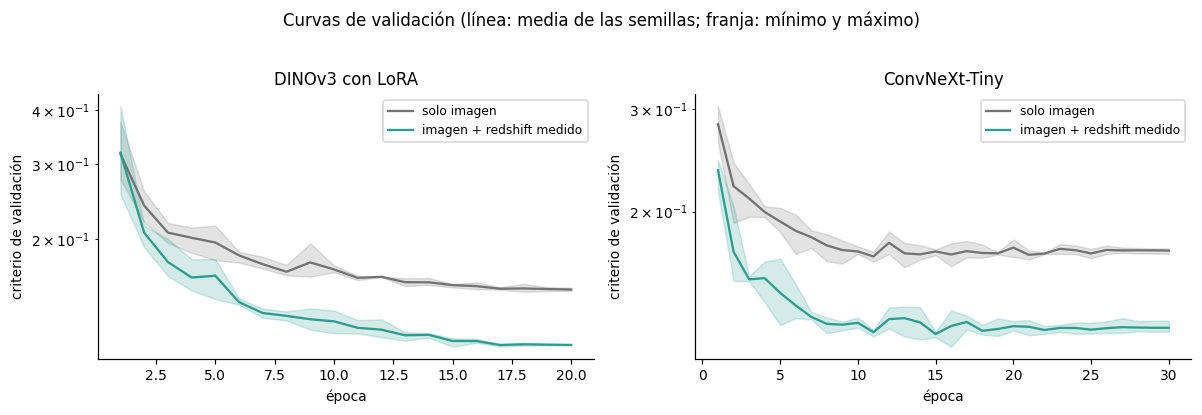

In [9]:
if FAMILIAS_NUEVAS:
    pares = [("dinov3_imagen", "dinov3_z", "DINOv3 con LoRA"), ("convnext_imagen", "convnext_z", "ConvNeXt-Tiny")]
    fig, ejes = plt.subplots(1, len(pares), figsize=(11, 3.6), sharey=False)
    for eje, (sin_z, con_z, titulo) in zip(np.atleast_1d(ejes), pares):
        for familia, color, etiqueta in ((sin_z, "0.45", "solo imagen"), (con_z, "#2a9d8f", "imagen + redshift medido")):
            curvas = np.stack([HISTORIALES[(familia, s)].criterio_validacion.to_numpy() for s in SEMILLAS])
            epocas = HISTORIALES[(familia, SEMILLAS[0])].epoca.to_numpy()
            eje.plot(epocas, curvas.mean(0), color=color, label=etiqueta); eje.fill_between(epocas, curvas.min(0), curvas.max(0), color=color, alpha=0.2)
        eje.set(xlabel="época", ylabel="criterio de validación", yscale="log", title=titulo); eje.legend(fontsize=8)
    plt.suptitle("Curvas de validación (línea: media de las semillas; franja: mínimo y máximo)", y=1.03); plt.tight_layout(); plt.show()

Con el redshift, las dos redes aprenden más rápido y llegan más abajo. ConvNeXt con redshift baja a cerca de 0.12 en las primeras diez épocas y después se estabiliza, mientras que su versión de solo imagen se queda alrededor de 0.165 desde la época 15. DINOv3 con redshift se separa de su versión de solo imagen a partir de la época 6 y termina cerca de 0.11, contra 0.15. Las franjas entre semillas son estrechas al final del entrenamiento, de modo que la diferencia no depende de la semilla, y ninguna curva sube en las últimas épocas, así que conservar la época con el menor criterio no esconde un sobreajuste fuerte.

## 7. EfficientNet-B3

EfficientNet (Tan y Le 2019) escala de forma conjunta la profundidad, el ancho y la resolución de una red de bloques de cuello de botella invertido con atención sobre los canales. La versión B3 se diseñó para imágenes de 300 × 300 píxeles, que es justamente el tamaño de nuestro recorte, y tiene 12 millones de parámetros. Zhong et al. (2024) la encontraron mejor que ResNet, Vision Transformer y Swin al estimar la masa estelar y la sSFR de galaxias de DESI. Nuestros resultados con ResNet50 y con un transformador de visión son distintos de los suyos, lo que probablemente se deba al preentrenamiento y al ajuste y no a la arquitectura, así que la tratamos como un candidato y no como un favorito.

Buscamos sus hiperparámetros con Optuna (Akiba et al. 2019), igual que en el modelo 3: el muestreo bayesiano TPE propone cada configuración a partir de las anteriores y la poda por *successive halving* detiene las que van peor que la mayoría en la misma época. Cada prueba dura lo mismo que un entrenamiento final, porque en el Avance 4 vimos que una búsqueda de 12 épocas favorecía configuraciones que al entrenar 30 épocas se sobreajustaban.

| Hiperparámetro | Espacio de búsqueda | Qué controla |
|---|---|---|
| Tasa de aprendizaje del extractor | 10⁻⁴ a 2 × 10⁻³ (logarítmica) | Cuánto se modifican los pesos preentrenados; Zhong et al. usan 3 × 10⁻⁴ |
| Tasa de las cabezas | 1 a 20 veces la del extractor (logarítmica) | Qué tan rápido aprenden las capas nuevas |
| *Weight decay* | 10⁻³ a 0.2 (logarítmica) | Regularización de los pesos |
| Decaimiento por capa | 0.6 a 1.0 | Cuánto menos cambian las capas iniciales que las finales; fue el hiperparámetro más importante en ConvNeXt |
| *Stochastic depth* | 0 a 0.3 | Regularización por omisión de bloques |
| Pérdida | Huber o MSE | Sensibilidad a errores grandes |
| Épocas de calentamiento | 1 a 3 | Estabilidad al inicio |

In [10]:
ESPECIFICACION_EFFICIENTNET = EspecificacionModelo(nombre_extractor=EXTRACTOR_EFFICIENTNET, preentrenado=PREENTRENADO)
CONFIGURACION_EFFICIENTNET = ConfiguracionEntrenamiento(epocas=EPOCAS_EFFICIENTNET, epocas_calentamiento=2, tamano_lote=32, tasa_extractor=3e-4,
                                                        tasa_cabeza=1e-3, decaimiento_pesos=0.05, decaimiento_por_capa=0.9, perdida="huber")

def proponer_efficientnet(prueba):
    return {"tasa_extractor": prueba.suggest_float("tasa_extractor", 1e-4, 2e-3, log=True),
            "factor_tasa_cabeza": prueba.suggest_float("factor_tasa_cabeza", 1.0, 20.0, log=True),
            "decaimiento_pesos": prueba.suggest_float("decaimiento_pesos", 1e-3, 0.2, log=True),
            "decaimiento_por_capa": prueba.suggest_float("decaimiento_por_capa", 0.6, 1.0),
            "tasa_drop_path": prueba.suggest_float("tasa_drop_path", 0.0, 0.3),
            "perdida": prueba.suggest_categorical("perdida", ["huber", "mse"]),
            "epocas_calentamiento": prueba.suggest_int("epocas_calentamiento", 1, 3)}

def configuracion_efficientnet(valores, semilla):
    espec = replace(ESPECIFICACION_EFFICIENTNET, tasa_drop_path=float(valores["tasa_drop_path"]))
    config = replace(CONFIGURACION_EFFICIENTNET, semilla=semilla, tasa_extractor=float(valores["tasa_extractor"]),
                     tasa_cabeza=float(valores["tasa_extractor"] * valores["factor_tasa_cabeza"]),
                     decaimiento_pesos=float(valores["decaimiento_pesos"]), decaimiento_por_capa=float(valores["decaimiento_por_capa"]),
                     perdida=str(valores["perdida"]), epocas_calentamiento=int(min(int(valores["epocas_calentamiento"]), max(1, EPOCAS_EFFICIENTNET - 1))))
    return espec, config

def evaluar_efficientnet(valores, al_terminar_epoca):
    espec, config = configuracion_efficientnet(valores, SEMILLAS[0])
    corrida = experimento.ejecutar_corrida(CONTEXTO, CARPETA_MODELO, "busqueda_efficientnet", espec, config, ENTRADA_EFFICIENTNET, DISPOSITIVO,
                                           VARIABLES_PISTA, al_terminar_epoca=al_terminar_epoca, guardar=False, registro=lambda *_: None)
    valor = corrida.resumen["mejor_criterio_validacion"]
    del corrida; torch.cuda.empty_cache()
    return valor

FAMILIA_EFFICIENTNET = f"efficientnet_{SUFIJO_PISTA}"
if INCLUIR_EFFICIENTNET:
    inicio = time.time()
    respaldo = lambda origen, destino: CONTEXTO.guardia.write(destino, lambda f: Path(f).write_bytes(Path(origen).read_bytes()), allow_replace=True)
    ESTUDIO_EFFICIENTNET = busqueda.ejecutar_busqueda(f"{NOMBRE_MODELO}_{FAMILIA_EFFICIENTNET}{'_lim' + str(LIMITE_GALAXIAS) if LIMITE_GALAXIAS else ''}",
                                                      CARPETA_MODELO / f"busqueda_{FAMILIA_EFFICIENTNET}.db", proponer_efficientnet, evaluar_efficientnet,
                                                      PRUEBAS_EFFICIENTNET, semilla=SEMILLAS[0], epocas_minimas_antes_de_podar=3, guardar_respaldo=respaldo,
                                                      registro=registro_busqueda)
    PRUEBAS_EFFICIENTNET_TABLA = busqueda.tabla_pruebas(ESTUDIO_EFFICIENTNET)
    print(f"Búsqueda: {len(PRUEBAS_EFFICIENTNET_TABLA)} pruebas en {(time.time() - inicio) / 60:.0f} min · "
          f"{(PRUEBAS_EFFICIENTNET_TABLA.estado == 'complete').sum()} terminadas, {(PRUEBAS_EFFICIENTNET_TABLA.estado == 'pruned').sum()} podadas")
    display(PRUEBAS_EFFICIENTNET_TABLA.head(8).round(5))
else:
    print("INCLUIR_EFFICIENTNET = False: no se busca ni se entrena EfficientNet.")

model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Búsqueda: 12 pruebas en 17 min · 2 terminadas, 10 podadas


,prueba,estado,criterio_validacion,epocas_usadas,minutos,tasa_extractor,factor_tasa_cabeza,decaimiento_pesos,decaimiento_por_capa,tasa_drop_path,perdida,epocas_calentamiento
0,1,complete,0.1288,20,6.0489,0.0006,8.3411,0.0011,0.9880,0.2497,huber,1
1,3,pruned,0.1456,9,2.8969,0.0006,8.3411,0.0011,0.9880,0.2497,huber,1
2,11,pruned,0.1475,9,2.8990,0.0005,13.3447,0.0923,0.9396,0.1665,huber,1
3,0,complete,0.1641,20,7.5163,0.0003,17.2547,0.0483,0.8395,0.0468,huber,3
4,10,pruned,0.1693,9,2.9036,0.0014,3.1052,0.0052,0.8737,0.2280,huber,1
5,7,pruned,0.1857,3,0.9677,0.0001,4.4080,0.0012,0.9637,0.0776,huber,2
6,8,pruned,0.2020,3,0.9670,0.0005,1.7398,0.1702,0.9101,0.2818,huber,3
7,6,pruned,0.2055,3,0.9695,0.0001,17.1605,0.1667,0.9234,0.0914,mse,2


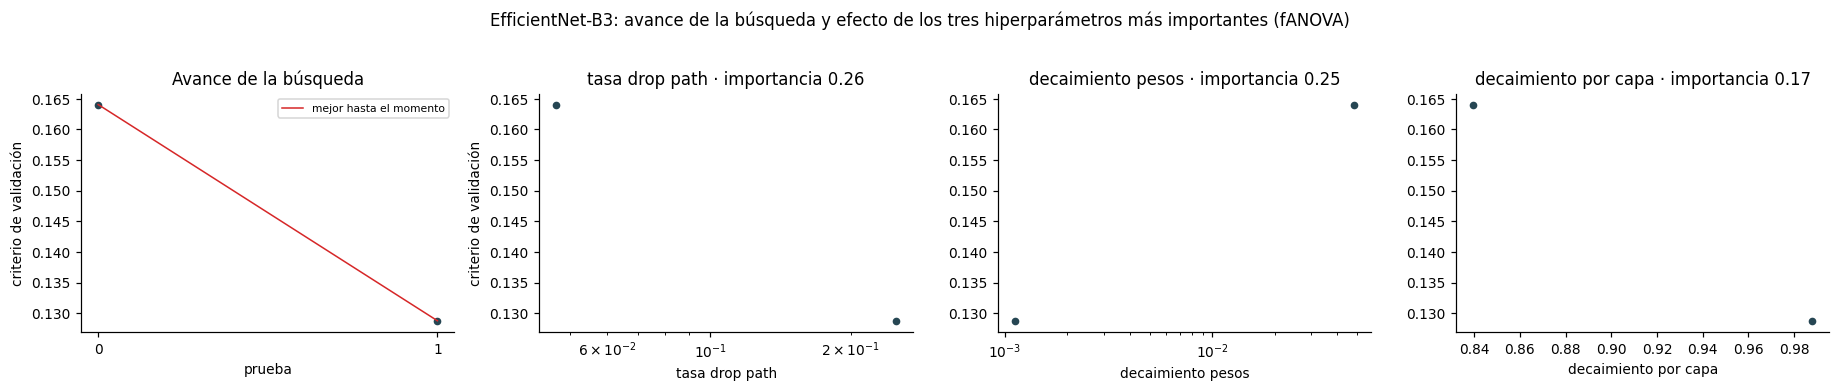

In [11]:
if INCLUIR_EFFICIENTNET:
    IMPORTANCIA_EFFICIENTNET = busqueda.importancia_hiperparametros(ESTUDIO_EFFICIENTNET)
    grafica_hiperparametros(PRUEBAS_EFFICIENTNET_TABLA, IMPORTANCIA_EFFICIENTNET, n=3,
                            titulo="EfficientNet-B3: avance de la búsqueda y efecto de los tres hiperparámetros más importantes (fANOVA)")

La búsqueda probó 12 configuraciones en 17 minutos y solo dos llegaron a las 20 épocas; la poda detuvo las otras diez en las épocas 3 o 9 porque iban peor que la mediana de las pruebas anteriores. La ganadora (prueba 1, criterio de 0.1288) usa una tasa de aprendizaje del extractor de 6 × 10⁻⁴, una tasa de las cabezas 8 veces mayor, casi sin decaimiento por capa (0.99), un *weight decay* bajo (0.001), un *stochastic depth* alto (0.25) y la pérdida de Huber. Con solo dos pruebas completas, la importancia de fANOVA de la gráfica no es informativa y no la interpretamos: aquí la búsqueda sirvió para descartar configuraciones malas, no para medir el efecto de cada hiperparámetro. Las tres semillas de la configuración ganadora alcanzaron criterios de 0.127 a 0.133 en su mejor época, en línea con lo que encontró la búsqueda.

Entrenamos la mejor configuración de la búsqueda con las tres semillas y exportamos sus predicciones. La búsqueda y los entrenamientos finales duran lo mismo, así que la configuración ganadora no necesita una segunda selección.

In [12]:
if INCLUIR_EFFICIENTNET:
    claves_efficientnet = ["tasa_extractor", "factor_tasa_cabeza", "decaimiento_pesos", "decaimiento_por_capa", "tasa_drop_path", "perdida", "epocas_calentamiento"]
    MEJOR_EFFICIENTNET = PRUEBAS_EFFICIENTNET_TABLA[PRUEBAS_EFFICIENTNET_TABLA.estado == "complete"].iloc[0]
    for semilla in SEMILLAS:
        espec, config = configuracion_efficientnet({k: MEJOR_EFFICIENTNET[k] for k in claves_efficientnet}, semilla)
        corrida = experimento.ejecutar_corrida(CONTEXTO, CARPETA_MODELO, FAMILIA_EFFICIENTNET, espec, config, ENTRADA_EFFICIENTNET, DISPOSITIVO,
                                               VARIABLES_PISTA, registro=registro_compacto)
        exportar_corrida(corrida, FAMILIA_EFFICIENTNET, NOMBRE_GPU, "este cuaderno")
        del corrida; torch.cuda.empty_cache()
    print("Configuración ganadora:", {k: (round(float(MEJOR_EFFICIENTNET[k]), 5) if k != "perdida" else MEJOR_EFFICIENTNET[k]) for k in claves_efficientnet})

época   5 · pérdida 0.0785 · validación 0.1517  ← mejor · 19 s
época  10 · pérdida 0.0555 · validación 0.1400  ← mejor · 19 s
época  15 · pérdida 0.0351 · validación 0.1273  ← mejor · 19 s
época  20 · pérdida 0.0275 · validación 0.1286 · 19 s
época   5 · pérdida 0.0769 · validación 0.1898 · 19 s
época  10 · pérdida 0.0560 · validación 0.1325  ← mejor · 19 s
época  15 · pérdida 0.0357 · validación 0.1360 · 19 s
época  20 · pérdida 0.0279 · validación 0.1334 · 19 s
época   5 · pérdida 0.0768 · validación 0.1547  ← mejor · 19 s
época  10 · pérdida 0.0553 · validación 0.1505 · 19 s
época  15 · pérdida 0.0362 · validación 0.1300 · 19 s
época  20 · pérdida 0.0281 · validación 0.1317 · 19 s
Configuración ganadora: {'tasa_extractor': 0.00061, 'factor_tasa_cabeza': 8.34111, 'decaimiento_pesos': 0.00112, 'decaimiento_por_capa': 0.98796, 'tasa_drop_path': 0.24973, 'perdida': 'huber', 'epocas_calentamiento': 1.0}


## 8. Comparación de los miembros en validación

Reunimos todas las redes en una tabla y las ordenamos por la métrica principal del protocolo común, el promedio del MSE normalizado (cuanto menor, mejor), acompañada del RMSE, el MAE y el R² de cada propiedad. Los valores son la media de las tres semillas y, para que sean comparables con los que reportamos en el Avance 4, se calculan sin TTA. Como referencia añadimos la variante E de ResNet50 del modelo 1 (semilla 42, con redshift medido), que es el mejor modelo individual del avance anterior.

,familia,entradas,criterio,desviación entre semillas,RMSE M*,RMSE SFR,RMSE D4000,R2 M*,R2 SFR,R2 D4000
0,dinov3_z,imagen + redshift medido,0.1124,0.0005,0.1116,0.5521,0.0693,0.9710,0.7748,0.9136
1,convnext_z,imagen + redshift medido,0.1204,0.0032,0.1099,0.5723,0.0726,0.9719,0.7581,0.9050
2,"resnet50_e (referencia, Luz)",imagen + redshift medido,0.1279,NaN,0.1088,0.5975,0.0730,0.9725,0.7362,0.9039
3,efficientnet_z,imagen + redshift medido,0.1287,0.0018,0.1122,0.5973,0.0733,0.9707,0.7364,0.9032
4,dinov3_imagen,imagen,0.1522,0.0017,0.2213,0.5871,0.0702,0.8861,0.7453,0.9112
5,convnext_imagen,imagen,0.1625,0.0031,0.2281,0.6069,0.0728,0.8789,0.7279,0.9045


,familia,min por entrenamiento,hardware,parámetros (M),ms por galaxia,horas de GPU por millón de galaxias
0,dinov3_z,24.04,NVIDIA A100-SXM4-40GB,308.192,2.692,0.748
1,convnext_z,6.112,NVIDIA A100-SXM4-40GB,28.412,0.451,0.125
2,"resnet50_e (referencia, Luz)",no reportado,no reportado,no reportado,no reportado,no reportado
3,efficientnet_z,6.392,NVIDIA A100-SXM4-40GB,11.878,0.396,0.11
4,dinov3_imagen,24.088,NVIDIA A100 (Colab),308.192,2.691,0.748
5,convnext_imagen,5.99,NVIDIA A100 (Colab),28.411,0.453,0.126


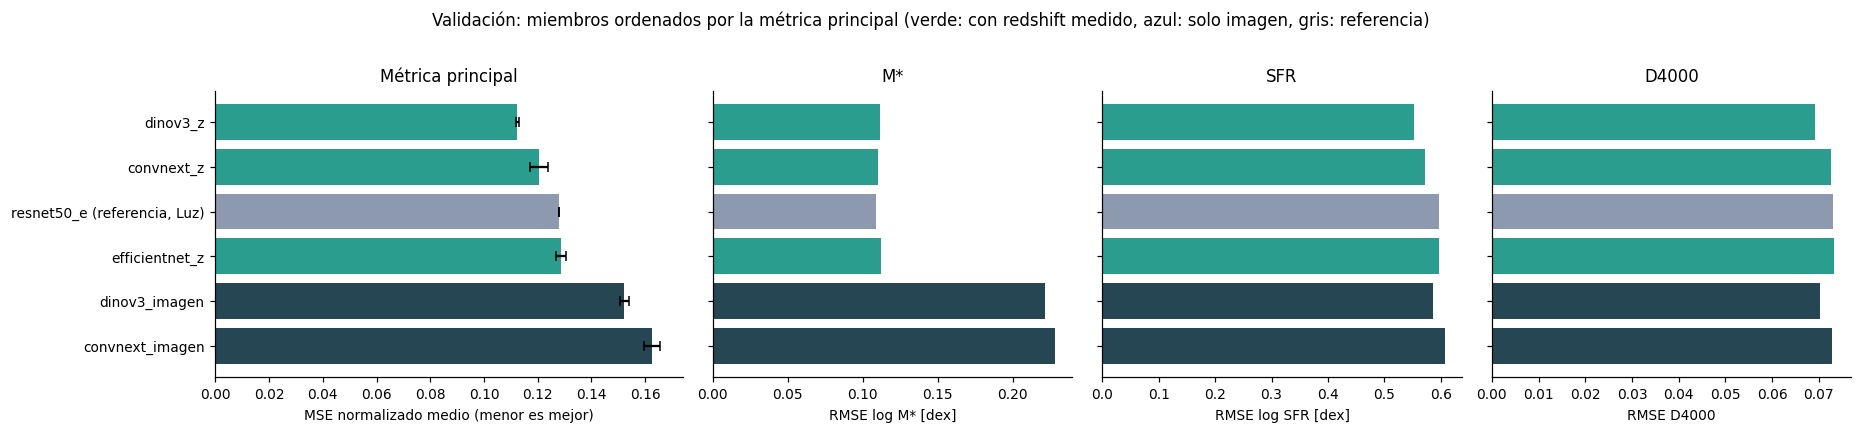

In [13]:
REFERENCIA_RESNET50_E = {"familia": "resnet50_e (referencia, Luz)", "entradas": "imagen + redshift medido", "criterio": 0.127879, "RMSE M*": 0.108829, "RMSE SFR": 0.597520, "RMSE D4000": 0.073037,
                         "MAE M*": 0.082898, "MAE SFR": 0.394586, "MAE D4000": 0.052342, "R2 M*": 0.972454, "R2 SFR": 0.736249, "R2 D4000": 0.903949}
filas = []
for familia in sorted({f for f, _ in PRED}):
    por_semilla = []
    for semilla in SEMILLAS:
        tabla = experimento.tabla_corrida(CONTEXTO, PRED_SIN_TTA[(familia, semilla)], "Validation").set_index("objetivo")
        por_semilla.append({"criterio": tabla.MSE_normalizado.mean(), **{f"{m} {CORTO[t]}": tabla.loc[t, m] for t in OBJETIVOS for m in ("RMSE", "MAE", "R2")}})
    medias = pd.DataFrame(por_semilla).mean()
    tiempos = pd.DataFrame(TIEMPOS)
    tiempos = tiempos[tiempos.familia == familia]
    filas.append({"familia": familia, "entradas": tiempos.entradas.iloc[0], **medias.to_dict(),
                  "desviación entre semillas": pd.DataFrame(por_semilla).criterio.std(ddof=1),
                  "min por entrenamiento": tiempos.minutos_entrenamiento.mean(), "parámetros (M)": tiempos.parametros_totales_M.iloc[0],
                  "ms por galaxia": tiempos.ms_por_galaxia.dropna().iloc[0], "hardware": tiempos.hardware.iloc[0]})
MIEMBROS = pd.DataFrame(filas).sort_values("criterio").reset_index(drop=True)
MIEMBROS["horas de GPU por millón de galaxias"] = MIEMBROS["ms por galaxia"].map(ensambles.horas_gpu_por_millon)
tabla_miembros = pd.concat([MIEMBROS, pd.DataFrame([REFERENCIA_RESNET50_E])], ignore_index=True).sort_values("criterio").reset_index(drop=True)
display(tabla_miembros[["familia", "entradas", "criterio", "desviación entre semillas", "RMSE M*", "RMSE SFR", "RMSE D4000", "R2 M*", "R2 SFR", "R2 D4000"]].round(4))
display(tabla_miembros[["familia", "min por entrenamiento", "hardware", "parámetros (M)", "ms por galaxia", "horas de GPU por millón de galaxias"]].round(3).fillna("no reportado"))

fig, ejes = plt.subplots(1, 4, figsize=(17, 0.8 + 0.5 * len(tabla_miembros)), sharey=True, gridspec_kw={"width_ratios": [1.3, 1, 1, 1]})
y_pos = np.arange(len(tabla_miembros))[::-1]
colores = ["#8d99ae" if "referencia" in f else ("#2a9d8f" if f.endswith("_z") else "#264653") for f in tabla_miembros.familia]
ejes[0].barh(y_pos, tabla_miembros.criterio, color=colores, xerr=tabla_miembros["desviación entre semillas"].fillna(0), capsize=3)
ejes[0].set(yticks=y_pos, yticklabels=tabla_miembros.familia, xlabel="MSE normalizado medio (menor es mejor)", title="Métrica principal")
for eje, t in zip(ejes[1:], OBJETIVOS):
    eje.barh(y_pos, tabla_miembros[f"RMSE {CORTO[t]}"], color=colores); eje.set(xlabel=f"RMSE {NOMBRES[t]}", title=CORTO[t])
plt.suptitle("Validación: miembros ordenados por la métrica principal (verde: con redshift medido, azul: solo imagen, gris: referencia)", y=1.02)
plt.tight_layout(); plt.show()

DINOv3 con redshift es el mejor modelo individual del equipo, con un criterio de 0.1124, 12 % menor que el de la ResNet50 E (0.1279), y con la menor desviación entre semillas (0.0005). ConvNeXt con redshift queda segundo (0.1204) y EfficientNet-B3 con redshift (0.1287) prácticamente empata con la ResNet50 E. La ventaja de los modelos nuevos sobre la ResNet50 E no está en la masa, donde los cuatro modelos con redshift tienen un RMSE de 0.109 a 0.112 dex, sino en la SFR (0.552 contra 0.598 dex) y, en menor medida, en el D4000 (0.069 contra 0.073). Esto confirma la hipótesis del planteamiento: con el redshift, DINOv3 alcanza a la ResNet50 en la masa y conserva su ventaja en la SFR y el D4000. En costo de uso, DINOv3 es el más caro (2.7 ms por galaxia, 0.75 horas de GPU por millón de galaxias) porque tiene 308 millones de parámetros, aunque con LoRA solo entrene 5 millones; EfficientNet-B3 es el más barato (0.40 ms).

## 9. ¿Qué cambia el redshift espectroscópico?

Para responder con rigor comparamos cada modelo con su versión de solo imagen sobre las mismas galaxias de validación y con las mismas semillas. La diferencia de RMSE entre las dos versiones, con su intervalo de confianza del 95 % por *bootstrap* pareado, se clasifica con la regla del proyecto: **mejor** o **peor** si el intervalo excluye el cero, **equivalente** si cabe dentro del margen que consideramos despreciable, **no concluyente** en otro caso.

Después miramos la causa. Si el redshift ayuda porque informa de la distancia, el error de la masa de la versión de solo imagen debe depender del redshift, y esa dependencia debe desaparecer con él. Lo revisamos con la mediana del residuo (predicción − etiqueta) en intervalos de redshift. Por último, medimos cuánto depende cada modelo del redshift revolviendo sus valores entre galaxias y viendo cuánto sube el error de cada propiedad: si la masa depende mucho de él y el D4000 casi nada, el modelo usa el redshift como lo hace la física.

Esta sección solo aplica cuando `PISTA = "con_redshift"`.

In [14]:
PARES = [("dinov3_imagen", "dinov3_z", "DINOv3 con LoRA"), ("convnext_imagen", "convnext_z", "ConvNeXt-Tiny")]
if VARIABLES_PISTA:
    filas = []
    for sin_z, con_z, titulo in PARES:
        for semilla in SEMILLAS:
            ps, pc = PRED[(sin_z, semilla)]["Validation"], PRED[(con_z, semilla)]["Validation"]
            for k, t in enumerate(OBJETIVOS):
                d, lo, hi = evaluacion.diferencia_pareada_rmse(Y_VALIDACION[:, k], pc[:, k], ps[:, k], n_remuestreos=N_REMUESTREOS)
                filas.append({"modelo": titulo, "semilla": semilla, "propiedad": CORTO[t], "ΔRMSE (con z − solo imagen)": d,
                              "IC 95 %": f"[{lo:+.3f}, {hi:+.3f}]", "veredicto": evaluacion.veredicto(lo, hi, MARGEN[CORTO[t]])})
    COMPARACION_REDSHIFT = pd.DataFrame(filas)
    display(COMPARACION_REDSHIFT.set_index(["modelo", "propiedad", "semilla"]).round(4))
else:
    print("PISTA = 'solo_imagen': no hay versiones con redshift que comparar.")

ΔRMSE (con z − solo imagen)           IC 95 %    veredicto
modelo          propiedad semilla                                                            
DINOv3 con LoRA M*        42                           -0.1059  [-0.116, -0.096]        mejor
                SFR       42                           -0.0381  [-0.050, -0.027]        mejor
                D4000     42                           -0.0011  [-0.002, -0.000]        mejor
                M*        7                            -0.1095  [-0.121, -0.099]        mejor
                SFR       7                            -0.0341  [-0.044, -0.024]        mejor
                D4000     7                            -0.0008  [-0.002, +0.000]  equivalente
                M*        2026                         -0.1061  [-0.117, -0.096]        mejor
                SFR       2026                         -0.0319  [-0.042, -0.022]        mejor
                D4000     2026                         -0.0013  [-0.002, -0.000]        mejor
ConvNeXt-Tiny   M*        42                           -0.1231  [-0.135, -0.113]        mejor
                SFR       42                           -0.0448  [-0.064, -0.026]        mejor
                D4000     42                            0.0012  [-0.001, +0.003]  equivalente
                M*        7                            -0.1157  [-0.127, -0.105]        mejor
                SFR       7                            -0.0312  [-0.048, -0.015]        mejor
                D4000     7                            -0.0030  [-0.005, -0.001]        mejor
                M*        2026                         -0.1134  [-0.125, -0.102]        mejor
                SFR       2026                         -0.0326  [-0.054, -0.012]        mejor
                D4000     2026                         -0.0012  [-0.003, +0.000]  equivalente

El redshift mejora la masa en las seis redes, entre 0.106 y 0.123 dex de RMSE según la red y la semilla, lo que equivale a la mitad del error de la versión de solo imagen, y todos los intervalos excluyen el cero con holgura. La SFR también mejora en las seis, aunque menos (de 0.031 a 0.045 dex). En el D4000 la diferencia es de una milésima: tres casos resultan «mejor», con intervalos que apenas excluyen el cero, y tres «equivalente». Es el patrón que predice la física: la masa y la SFR dependen de la luminosidad, que necesita la distancia, y el D4000 es un cociente de flujos que no depende de ella.

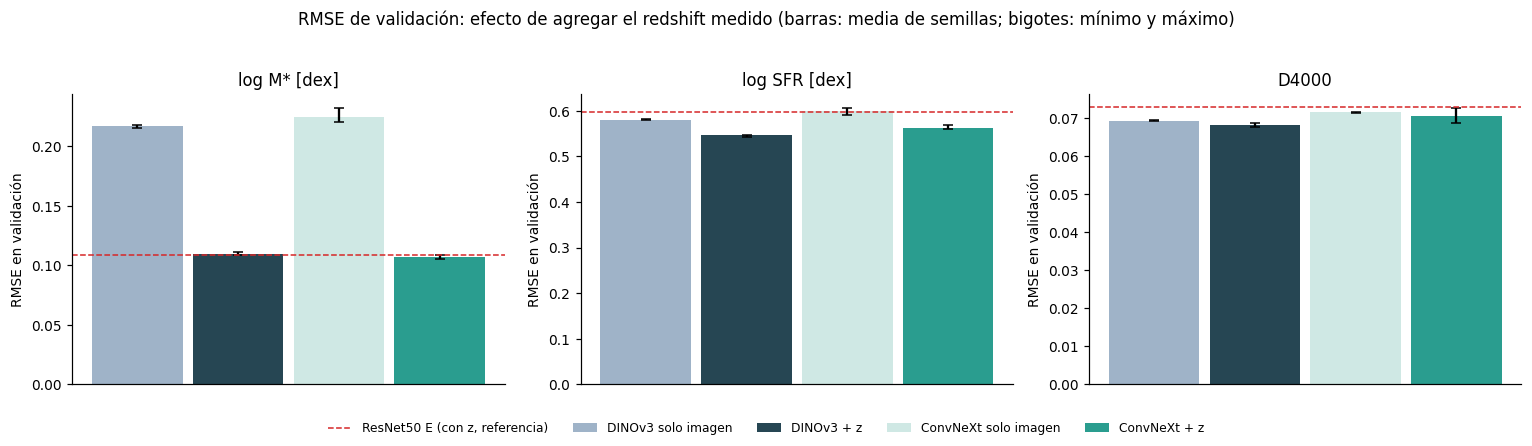

In [15]:
if VARIABLES_PISTA:
    fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))
    ancho = 0.2
    for k, (eje, t) in enumerate(zip(ejes, OBJETIVOS)):
        for i, (familia, color, etiqueta) in enumerate((("dinov3_imagen", "#9fb3c8", "DINOv3 solo imagen"), ("dinov3_z", "#264653", "DINOv3 + z"),
                                                       ("convnext_imagen", "#cfe8e4", "ConvNeXt solo imagen"), ("convnext_z", "#2a9d8f", "ConvNeXt + z"))):
            rmse = np.array([np.sqrt(np.mean((PRED[(familia, s)]["Validation"][:, k] - Y_VALIDACION[:, k]) ** 2)) for s in SEMILLAS])
            eje.bar(i * ancho, rmse.mean(), ancho * 0.9, color=color, yerr=[[rmse.mean() - rmse.min()], [rmse.max() - rmse.mean()]], capsize=3, label=etiqueta)
        eje.axhline(REFERENCIA_RESNET50_E[f"RMSE {CORTO[t]}"], color="C3", ls="--", lw=1, label="ResNet50 E (con z, referencia)")
        eje.set(xticks=[], ylabel="RMSE en validación", title=NOMBRES[t])
    manijas, etiquetas = ejes[0].get_legend_handles_labels()
    fig.legend(manijas, etiquetas, loc="lower center", ncol=5, fontsize=8, frameon=False)
    plt.suptitle("RMSE de validación: efecto de agregar el redshift medido (barras: media de semillas; bigotes: mínimo y máximo)", y=1.03)
    plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

La gráfica resume el efecto con las predicciones con TTA. En la masa, las dos versiones con redshift bajan el RMSE a la mitad, de unos 0.22 a unos 0.11 dex, y quedan al nivel de la ResNet50 E (línea roja), con ConvNeXt ligeramente por debajo. En la SFR, las dos versiones con redshift quedan por debajo de la ResNet50 E, y DINOv3 con redshift es la mejor (0.55 dex). En el D4000, las cuatro versiones ya superaban a la ResNet50 E sin el redshift, y el redshift casi no las cambia. Los bigotes, que van del mínimo al máximo de las tres semillas, son mucho menores que las diferencias entre versiones.

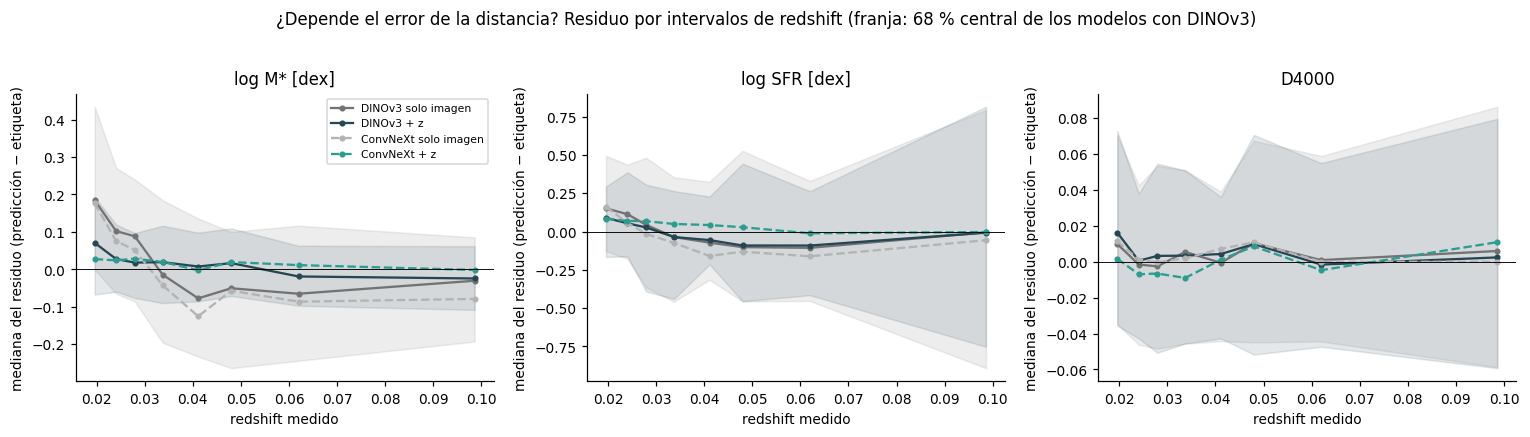

In [16]:
def mediana_por_intervalos(x, residuo, n=8):
    n = int(max(2, min(n, len(x) // 12)))          # con pocas galaxias, menos intervalos
    bordes = np.quantile(x, np.linspace(0, 1, n + 1)); centro, med, p16, p84 = [], [], [], []
    for a, b in zip(bordes[:-1], bordes[1:]):
        s = (x >= a) & (x <= b)
        if s.sum() >= 4:
            centro.append(np.median(x[s])); med.append(np.median(residuo[s])); p16.append(np.percentile(residuo[s], 16)); p84.append(np.percentile(residuo[s], 84))
    return map(np.array, (centro, med, p16, p84))

def promedio_de_semillas(familia, particion="Validation"):
    return np.mean([PRED[(familia, s)][particion] for s in SEMILLAS], axis=0)

if VARIABLES_PISTA:
    fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True)
    for k, (eje, t) in enumerate(zip(ejes, OBJETIVOS)):
        for familia, color, estilo, etiqueta in (("dinov3_imagen", "0.45", "-", "DINOv3 solo imagen"), ("dinov3_z", "#264653", "-", "DINOv3 + z"),
                                                 ("convnext_imagen", "0.7", "--", "ConvNeXt solo imagen"), ("convnext_z", "#2a9d8f", "--", "ConvNeXt + z")):
            cx, med, p16, p84 = mediana_por_intervalos(Z_VALIDACION, promedio_de_semillas(familia)[:, k] - Y_VALIDACION[:, k])
            eje.plot(cx, med, estilo, marker="o", ms=3, color=color, label=etiqueta)
            if estilo == "-":
                eje.fill_between(cx, p16, p84, color=color, alpha=0.12)
        eje.axhline(0, color="k", lw=0.6); eje.set(xlabel="redshift medido", ylabel="mediana del residuo (predicción − etiqueta)", title=NOMBRES[t])
    ejes[0].legend(fontsize=7)
    plt.suptitle("¿Depende el error de la distancia? Residuo por intervalos de redshift (franja: 68 % central de los modelos con DINOv3)", y=1.03)
    plt.tight_layout(); plt.show()

Este gráfico muestra el mecanismo. Sin redshift, las dos redes sobrestiman en unos 0.18 dex la masa de las galaxias más cercanas (z ≈ 0.02) y la subestiman entre 0.08 y 0.12 dex alrededor de z ≈ 0.04. Sin la distancia, la red interpreta el brillo aparente como si todas las galaxias estuvieran a una distancia típica de la muestra, y las cercanas, que se ven más brillantes, parecen más masivas. Con el redshift, la mediana del residuo de la masa se queda dentro de ±0.03 dex a partir de z ≈ 0.025 en las dos redes, y solo DINOv3 conserva +0.07 dex en el primer intervalo. En la SFR el efecto es menor: ConvNeXt con redshift reduce la tendencia a menos de 0.08 dex, y DINOv3 conserva una tendencia parecida con y sin redshift, de +0.1 a −0.1 dex. En el D4000 no hay tendencia con ninguna versión.

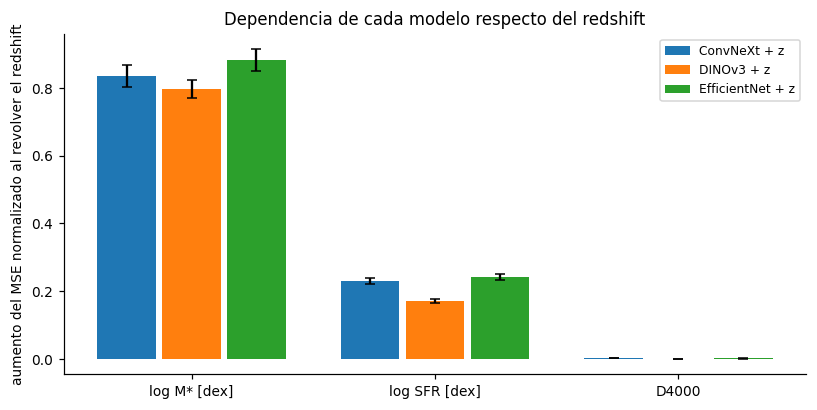

propiedad,M*,SFR,D4000
modelo,,,
ConvNeXt + z,0.8348,0.2301,0.0019
DINOv3 + z,0.7965,0.1711,0.0000
EfficientNet + z,0.8822,0.2418,0.0009


In [17]:
if VARIABLES_PISTA:
    filas = []
    for familia, titulo in (("dinov3_z", "DINOv3 + z"), ("convnext_z", "ConvNeXt + z")) + (((FAMILIA_EFFICIENTNET, "EfficientNet + z"),) if INCLUIR_EFFICIENTNET else ()):
        corrida = experimento.recuperar_corrida(CONTEXTO, CARPETAS_CORRIDAS[(familia, SEMILLAS[0])], DISPOSITIVO)
        conjunto = experimento.conjunto_de(CONTEXTO, corrida, "Validation", DISPOSITIVO)
        base = CONTEXTO.a_escala_original(interpretacion.predecir_con_modificacion(corrida.modelo, corrida.preparador, conjunto))
        for repeticion in range(5):
            permutada = CONTEXTO.a_escala_original(interpretacion.predecir_con_modificacion(corrida.modelo, corrida.preparador, conjunto,
                                                                                            escalar_permutado=0, semilla=repeticion))
            for k, t in enumerate(OBJETIVOS):
                filas.append({"modelo": titulo, "propiedad": CORTO[t], "repetición": repeticion,
                              "aumento del MSE normalizado": np.mean(((permutada[:, k] - Y_VALIDACION[:, k]) / ESCALA[k]) ** 2)
                                                             - np.mean(((base[:, k] - Y_VALIDACION[:, k]) / ESCALA[k]) ** 2)})
        del corrida, conjunto; torch.cuda.empty_cache()
    IMPORTANCIA_REDSHIFT = pd.DataFrame(filas)
    resumen_importancia = IMPORTANCIA_REDSHIFT.groupby(["modelo", "propiedad"])["aumento del MSE normalizado"].agg(["mean", "std"]).reset_index()
    fig, eje = plt.subplots(figsize=(7.5, 3.8))
    modelos = list(dict.fromkeys(resumen_importancia.modelo)); ancho = 0.8 / len(modelos)
    for i, m in enumerate(modelos):
        r = resumen_importancia[resumen_importancia.modelo == m].set_index("propiedad").reindex([CORTO[t] for t in OBJETIVOS])
        eje.bar(np.arange(3) + i * ancho, r["mean"], ancho * 0.9, yerr=r["std"], capsize=3, label=m)
    eje.set(xticks=np.arange(3) + ancho * (len(modelos) - 1) / 2, xticklabels=[NOMBRES[t] for t in OBJETIVOS],
            ylabel="aumento del MSE normalizado al revolver el redshift", title="Dependencia de cada modelo respecto del redshift")
    eje.legend(fontsize=8); plt.tight_layout(); plt.show()
    display(resumen_importancia.pivot(index="modelo", columns="propiedad", values="mean").reindex(columns=[CORTO[t] for t in OBJETIVOS]).round(4))

Al revolver el redshift entre galaxias, el MSE normalizado de la masa sube entre 0.80 y 0.88, unas 30 veces el error de cada red en esa propiedad, así que las tres dependen del redshift para la masa casi por completo. La SFR depende de él en menor medida (aumentos de 0.17 a 0.24) y el D4000 prácticamente nada (menos de 0.002). Es el orden que esperamos por la física, lo que indica que las redes usan el redshift como distancia y no como un atajo propio de esta muestra. DINOv3 es la que menos depende del redshift en la masa y en la SFR.

## 10. Diversidad entre los miembros

Los ensambles ganan cuando sus miembros se equivocan de formas distintas. Para anticipar cuánto se puede ganar medimos la correlación de los residuos entre las familias, con el promedio de las semillas de cada una: una correlación cercana a 1 significa que dos modelos cometen casi los mismos errores y combinarlos aportaría poco; una menor señala errores que se compensan. Después descomponemos el error de un promedio simple de todas las familias, según Krogh y Vedelsby (1995): el error del ensamble es el error medio de los miembros menos su ambigüedad, que es lo que se desacuerdan. Una ambigüedad grande frente al error medio es la ganancia que un ensamble puede capturar.

Por último, comprobamos qué tan bien reproduce cada modelo nuevo el rango de las etiquetas. Las regresiones tienden a comprimir las predicciones hacia el centro de la distribución, y una pendiente de la predicción contra la etiqueta menor que 1 lo cuantifica; un meta-aprendiz del cuaderno de ensambles puede corregir parte de esa compresión.

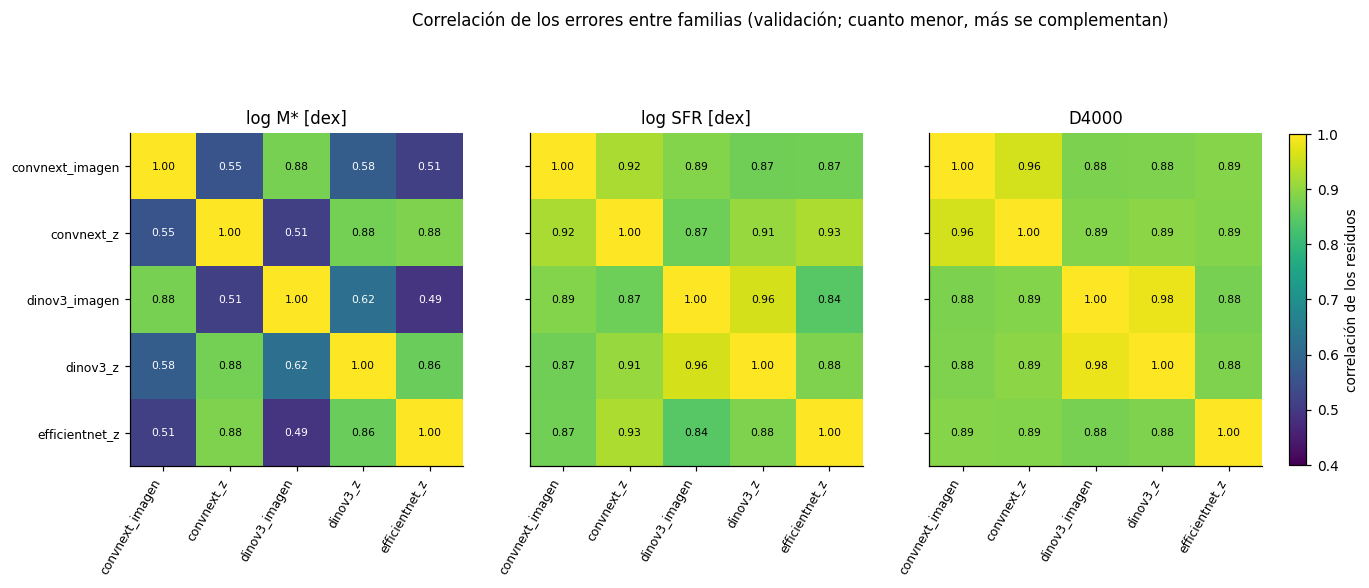

,error medio de los miembros,ambigüedad,error del ensamble
propiedad,,,
M*,0.0601,0.0209,0.0392
SFR,0.2372,0.0209,0.2163
D4000,0.0804,0.0064,0.0741


Promedio simple de las 5 familias: criterio 0.1099


In [18]:
FAMILIAS = sorted({f for f, _ in PRED})
P_FAMILIAS = np.stack([promedio_de_semillas(f) for f in FAMILIAS])
correlaciones = ensambles.correlacion_residuos(P_FAMILIAS, Y_VALIDACION)
minimo_corr = float(min(0.5, np.floor(10 * correlaciones.min()) / 10))
fig, ejes = plt.subplots(1, 3, figsize=(16, 5.2), sharey=True)
for k, (eje, matriz, t) in enumerate(zip(ejes, correlaciones, OBJETIVOS)):
    imagen = eje.imshow(matriz, vmin=minimo_corr, vmax=1, cmap="viridis")
    eje.set(xticks=range(len(FAMILIAS)), yticks=range(len(FAMILIAS)), title=NOMBRES[t])
    eje.set_xticklabels(FAMILIAS, rotation=60, ha="right", fontsize=8)
    if k == 0:
        eje.set_yticklabels(FAMILIAS, fontsize=8)
    for i in range(len(FAMILIAS)):
        for j in range(len(FAMILIAS)):
            eje.text(j, i, f"{matriz[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w" if matriz[i, j] < (minimo_corr + 1) / 2 else "k")
fig.colorbar(imagen, ax=ejes, shrink=0.75, pad=0.02, label="correlación de los residuos")
plt.suptitle("Correlación de los errores entre familias (validación; cuanto menor, más se complementan)", y=1.0); plt.show()
display(ensambles.descomposicion_ambiguedad(P_FAMILIAS, Y_VALIDACION, ESCALA, nombres_objetivos=[CORTO[t] for t in OBJETIVOS]).set_index("propiedad").round(4))
print(f"Promedio simple de las {len(FAMILIAS)} familias: criterio {ensambles.criterio(Y_VALIDACION, P_FAMILIAS.mean(0), ESCALA):.4f}")

Las redes con redshift cometen errores muy parecidos entre sí: sus residuos tienen correlaciones de 0.86 a 0.88 en la masa, de 0.88 a 0.93 en la SFR y de 0.88 a 0.89 en el D4000. Entre una red con redshift y una sin él, la correlación en la masa baja a valores de 0.49 a 0.62, porque sus errores de masa tienen causas distintas, pero eso no ayuda: las redes sin redshift tienen el doble de error en la masa, y el promedio simple de las cinco familias (0.1099) es peor que el promedio de las semillas de DINOv3 con redshift con las mismas predicciones (0.1081). Por eso los ensambles heterogéneos de la pista con redshift combinan solo las tres familias con redshift. En esta mezcla de cinco familias, la ambigüedad es grande en la masa (0.021 frente a un error medio de 0.060) justamente por las redes sin redshift, y pequeña en la SFR (0.021 frente a 0.237), que es la propiedad más difícil.

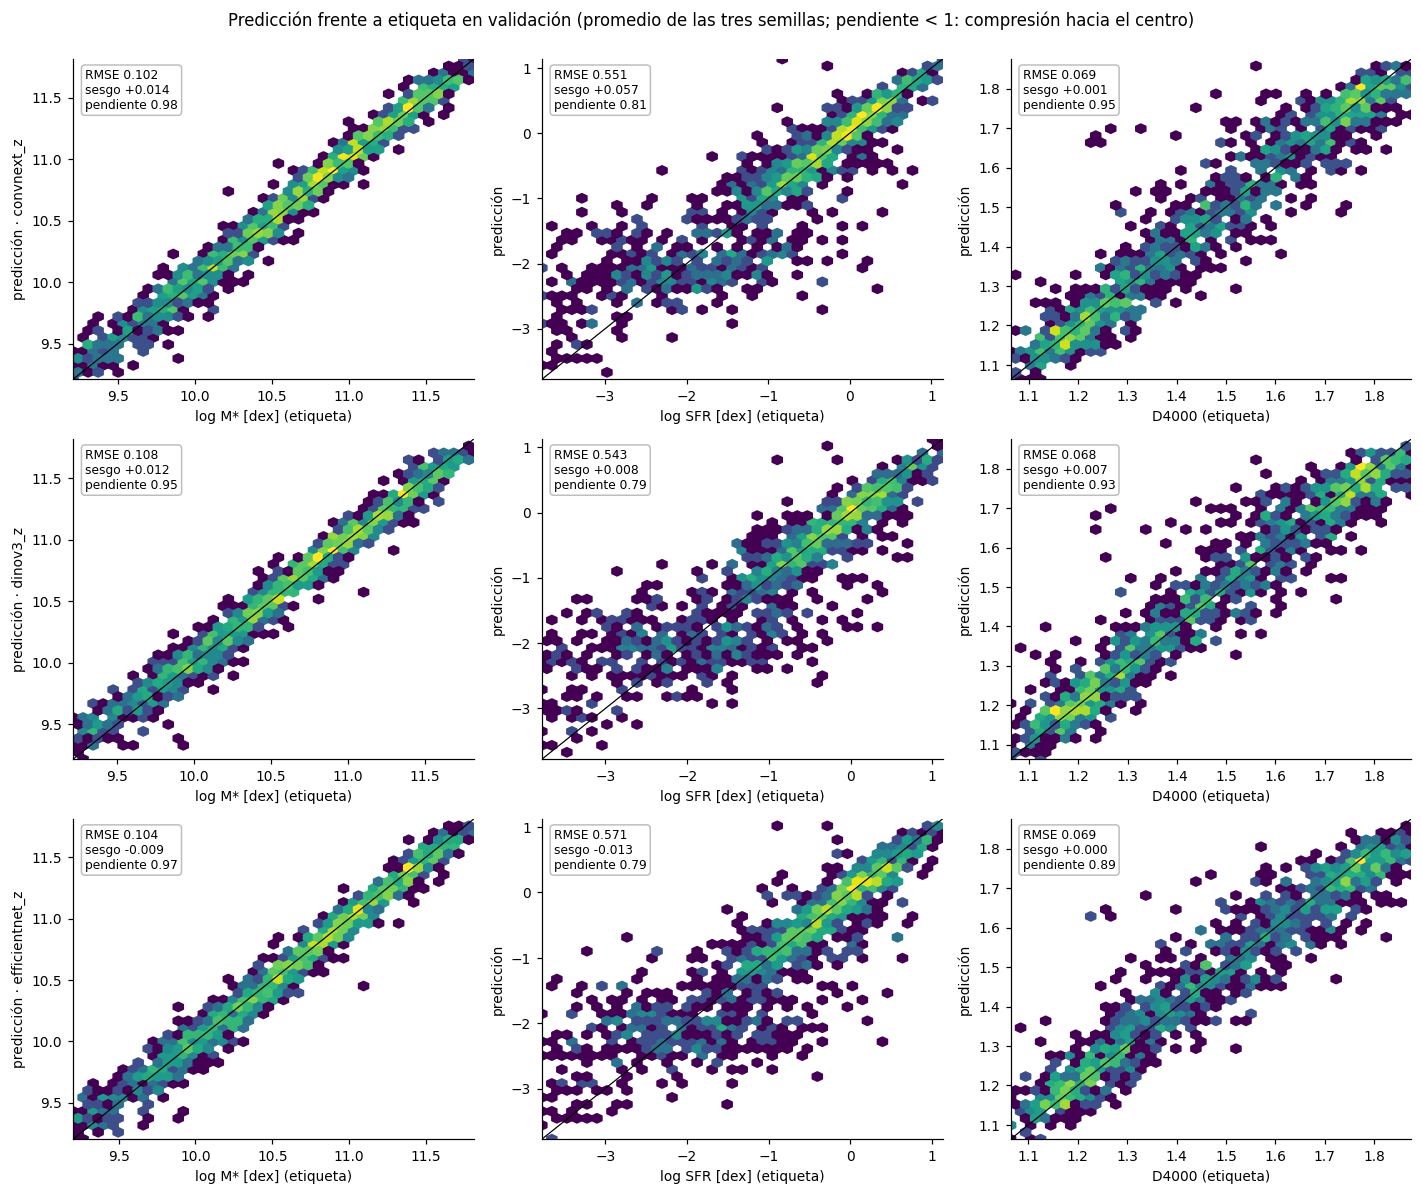

In [19]:
nuevas = [f for f in FAMILIAS if f in FAMILIAS_NUEVAS or f == FAMILIA_EFFICIENTNET] or FAMILIAS[:2]
fig, ejes = plt.subplots(len(nuevas), 3, figsize=(13, 3.6 * len(nuevas)), squeeze=False)
for fila, familia in enumerate(nuevas):
    prediccion = promedio_de_semillas(familia)
    for k, t in enumerate(OBJETIVOS):
        y, p = Y_VALIDACION[:, k], prediccion[:, k]
        lim = np.percentile(np.r_[y, p], [0.5, 99.5]); eje = ejes[fila, k]
        eje.hexbin(y, p, gridsize=40, cmap="viridis", mincnt=1, bins="log", extent=(*lim, *lim)); eje.plot(lim, lim, "k-", lw=0.8)
        m = evaluacion.metricas(y, p)
        eje.text(0.03, 0.97, f"RMSE {m['RMSE']:.3f}\nsesgo {m['sesgo']:+.3f}\npendiente {ensambles.pendiente_de_calibracion(y, p):.2f}", transform=eje.transAxes, va="top",
                 fontsize=8, bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="0.7"))
        eje.set(xlim=lim, ylim=lim, xlabel=f"{NOMBRES[t]} (etiqueta)", ylabel=f"predicción · {familia}" if k == 0 else "predicción")
plt.suptitle("Predicción frente a etiqueta en validación (promedio de las tres semillas; pendiente < 1: compresión hacia el centro)", y=1.0)
plt.tight_layout(); plt.show()

Las tres redes nuevas reproducen bien el rango de la masa (pendientes de 0.95 a 0.98) y del D4000 (de 0.89 a 0.95), pero comprimen la SFR hacia el centro (pendientes de 0.79 a 0.81). La compresión viene de las galaxias apagadas: por debajo de log SFR ≈ −2, las predicciones se acumulan cerca de −2 aunque la etiqueta llegue a −3.5, porque en la imagen una galaxia que casi no forma estrellas se ve muy parecida a otra que forma un poco más. ConvNeXt con redshift tiene además un sesgo de +0.057 dex en la SFR que las otras dos no tienen (+0.008 y −0.013), una diferencia que una combinación con pesos puede compensar.

## 11. Exportación para el cuaderno de ensambles

Guardamos los archivos que necesita el cuaderno de ensambles. Las predicciones de cada red ya están en la carpeta `predicciones`, con un archivo por familia y semilla. Medimos también el tiempo de uso de la ResNet50 del modelo 1 en esta misma GPU, para que el costo de todos los ensambles se compare en el mismo equipo. Agregamos `tiempos_modelos.csv`, con el costo de entrenar y de usar cada red, `escala_train.json`, con la desviación de cada propiedad en las galaxias de entrenamiento (necesaria para calcular la métrica principal sin acceso al catálogo) y un manifiesto con la pista y las versiones. Todo se comprime en un `.zip` para copiarlo al repositorio, en la carpeta `Avance 5. Modelo final/predicciones/`. Los archivos pesan unos kilobytes.

**Formato común.** Cualquier red que deba entrar a los ensambles, de este cuaderno o de otro, necesita un archivo `pred_<familia>_s<semilla>.csv` con las columnas `mangaid, particion, redshift, y_log_mstar, y_log_sfr, y_d4000, pred_log_mstar, pred_log_sfr, pred_d4000, familia, semilla, tta`, con las galaxias de validación y de prueba (`particion` igual a `Validation` o `Test`) y las predicciones en la escala original. La función `predicciones.tabla_predicciones` del paquete construye exactamente esa tabla.

In [20]:
# Tiempo de uso de las ResNet50 del modelo 1, medido en esta misma GPU con la misma arquitectura (ResNet50 con cabezas de
# 2,048 + k entradas) y la misma imagen de 300 × 300 px. La duración de una predicción no depende de los valores de los pesos,
# así que usamos pesos aleatorios; sus tiempos de entrenamiento son los que reportó Luz y los agrega el cuaderno de ensambles.
from src.modelos_alternativos.arquitecturas import construir_modelo
def medir_arquitectura(nombre_extractor, variables):
    modelo = construir_modelo(EspecificacionModelo(nombre_extractor=nombre_extractor, preentrenado=False), len(variables), len(OBJETIVOS))
    corrida = experimento.ResultadoCorrida("medicion", None, modelo.to(DISPOSITIVO).eval(), experimento.crear_preparador(CONTEXTO, ENTRADA_BASE),
                                           {"configuracion": {}}, None, False, tuple(variables))
    ms = experimento.tiempo_inferencia_ms(CONTEXTO, corrida, DISPOSITIVO)
    del corrida, modelo; torch.cuda.empty_cache()
    return ms
for familias, variables in ((("resnet50_e", "resnet50_d"), ("redshift",)), (("resnet50_g", "resnet50_f"), ())):
    ms = medir_arquitectura("resnet50", variables)
    for familia in familias:
        TIEMPOS.append({"familia": familia, "semilla": np.nan, "origen": "medición de inferencia (pesos aleatorios)", "hardware": NOMBRE_GPU,
                        "entradas": "imagen + redshift medido" if variables else "imagen", "minutos_entrenamiento": np.nan,
                        "parametros_totales_M": np.nan, "parametros_entrenables_M": np.nan, "ms_por_galaxia": ms})
    print(f"ResNet50 ({'imagen + redshift' if variables else 'solo imagen'}): {ms:.2f} ms por galaxia en {NOMBRE_GPU}")

ResNet50 (imagen + redshift): 0.44 ms por galaxia en NVIDIA A100-SXM4-40GB
ResNet50 (solo imagen): 0.44 ms por galaxia en NVIDIA A100-SXM4-40GB


In [21]:
TIEMPOS_TABLA = pd.DataFrame(TIEMPOS)
CONTEXTO.guardia.write(CARPETA_PREDICCIONES / "tiempos_modelos.csv", lambda f: TIEMPOS_TABLA.to_csv(f, index=False), allow_replace=True)
CONTEXTO.guardia.write_json(CARPETA_PREDICCIONES / "escala_train.json", {t: float(ESCALA[k]) for k, t in enumerate(OBJETIVOS)}, allow_replace=True)
CONTEXTO.guardia.write_json(CARPETA_PREDICCIONES / "manifiesto.json",
                            {"pista": PISTA, "familias": sorted({f for f, _ in PRED}), "semillas": list(SEMILLAS), "tta": USAR_TTA,
                             "galaxias": {p: int(len(i)) for p, i in INDICES.items()}, "commit": COMMIT, "gpu": NOMBRE_GPU,
                             "fecha_utc": datetime.now(timezone.utc).isoformat()}, allow_replace=True)
import zipfile
RUTA_ZIP = CARPETA_MODELO / f"predicciones_avance5_{PISTA}.zip"
def escribir_zip(destino):
    with zipfile.ZipFile(destino, "w", zipfile.ZIP_DEFLATED) as z:
        for archivo in sorted(CARPETA_PREDICCIONES.glob("*")):
            z.write(archivo, f"predicciones/{archivo.name}")
CONTEXTO.guardia.write(RUTA_ZIP, escribir_zip, allow_replace=True)
verificacion = predicciones.leer_carpeta(CARPETA_PREDICCIONES)
resumen_exportacion = verificacion.groupby(["familia", "semilla", "particion"]).size().unstack("particion").assign(tta=verificacion.groupby(["familia", "semilla"]).tta.first())
display(resumen_exportacion)
print(f"{verificacion.groupby(['familia', 'semilla']).ngroups} redes exportadas · {RUTA_ZIP}")
if EN_COLAB:
    from google.colab import files
    files.download(str(RUTA_ZIP))

particion                Test  Validation   tta
familia         semilla                        
convnext_imagen 7         917        1261  True
                42        917        1261  True
                2026      917        1261  True
convnext_z      7         917        1261  True
                42        917        1261  True
                2026      917        1261  True
dinov3_imagen   7         917        1261  True
                42        917        1261  True
                2026      917        1261  True
dinov3_z        7         917        1261  True
                42        917        1261  True
                2026      917        1261  True
efficientnet_z  7         917        1261  True
                42        917        1261  True
                2026      917        1261  True

15 redes exportadas · /content/drive/MyDrive/resultados_modelos_alternativos/avance5_modelos_base/predicciones_avance5_con_redshift.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusiones

La hipótesis del cuaderno se confirma. Con el redshift espectroscópico como entrada, DINOv3 con LoRA es el mejor modelo individual del equipo, con un criterio de validación de 0.1124, 12 % menor que el de la ResNet50 E (0.1279), y ConvNeXt con redshift queda segundo (0.1204). El redshift reduce a la mitad el error de la masa en las dos arquitecturas y mejora la SFR entre 0.03 y 0.04 dex, mientras que el D4000 casi no cambia. Los residuos por intervalos de redshift y la importancia por permutación muestran el mismo mecanismo: sin la distancia, la red confunde a las galaxias cercanas con galaxias más masivas, y con ella ese sesgo desaparece.

EfficientNet-B3 alcanzó a la ResNet50 E (0.1287) con el menor costo de uso de todas las redes (0.40 ms por galaxia), pero no superó a ConvNeXt ni a DINOv3. No reproducimos la ventaja que encontraron Zhong et al. (2024), aunque las condiciones son distintas: ellos entrenaron con 60,000 galaxias y etiquetas de SDSS, y nosotros con 7,121.

Las redes con redshift se equivocan de formas muy parecidas (correlaciones de los residuos de 0.86 a 0.93), así que la ganancia de combinarlas será modesta. Exportamos las predicciones de validación y de prueba de las quince redes para el cuaderno de ensambles heterogéneos; este cuaderno no calcula ninguna métrica con el conjunto de prueba.

## 13. Referencias

Akiba, T., Sano, S., Yanase, T., Ohta, T. y Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. *Proceedings of the 25th ACM SIGKDD*, 2623–2631.

Hu, E. J., Shen, Y., Wallis, P., et al. (2022). LoRA: Low-rank adaptation of large language models. *ICLR*.

Krogh, A. y Vedelsby, J. (1995). Neural network ensembles, cross validation, and active learning. *Advances in Neural Information Processing Systems 7*, 231–238.

Liu, Z., Mao, H., Wu, C.-Y., Feichtenhofer, C., Darrell, T. y Xie, S. (2022). A ConvNet for the 2020s. *CVPR*, 11976–11986.

Siméoni, O., Vo, H. V., Seitzer, M., et al. (2025). DINOv3. arXiv:2508.10104.

Studer, S., Bui, T. B., Drescher, C., et al. (2021). Towards CRISP-ML(Q): A machine learning process model with quality assurance methodology. *Machine Learning and Knowledge Extraction*, 3, 392–413.

Tan, M. y Le, Q. V. (2019). EfficientNet: Rethinking model scaling for convolutional neural networks. *ICML*, 6105–6114.

Zhong, J., Deng, Z., Li, X., Wang, L., Yang, H., Li, H. y Zhao, X. (2024). Estimation of stellar mass and star formation rate based on galaxy images. *Monthly Notices of the Royal Astronomical Society*, 531(1), 2011–2027.